# **02 - Modeling**

In [1]:
import warnings
warnings.filterwarnings("ignore")

import sys, os, json, pickle, time
sys.path.append("..")

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, accuracy_score, f1_score

from scripts.preprocess import TARGET, build_preprocessor, get_fit_params
from scripts.feature_engineering import add_features, NUMERIC_COLUMNS, CATEGORICAL_COLUMNS
from scripts.train import build_pipeline, tune_pipeline, select_n_estimators, SEARCH_SPACE
from sklearn.preprocessing import FunctionTransformer

os.makedirs("../models", exist_ok=True)
os.makedirs("../reports/figures", exist_ok=True)

# **1. Read Dataset**

In [2]:
df = pd.read_csv("../data/train.csv")
print(df.shape)
df.head()

(533465, 17)


,building_id,district_id,vdcmun_id,ward_id,count_floors_pre_eq,age_building,plinth_area_sq_ft,height_ft_pre_eq,land_surface_condition,foundation_type,roof_type,ground_floor_type,other_floor_type,position,plan_configuration,damage_grade,superstructure
0,280803013271,28,2802,280202,3,42,504,21,Flat,Mud mortar-Stone/Brick,Bamboo/Timber-Light roof,Mud,TImber/Bamboo-Mud,Attached-2 side,Rectangular,Grade 5,has_superstructure_mud_mortar_stone
1,311908002031,31,3104,310416,2,8,380,16,Flat,Cement-Stone/Brick,Bamboo/Timber-Heavy roof,Mud,Timber-Planck,Not attached,Rectangular,Grade 1,has_superstructure_cement_mortar_brick
2,310303000362,31,3111,311106,2,37,375,16,Moderate slope,Mud mortar-Stone/Brick,Bamboo/Timber-Light roof,Mud,TImber/Bamboo-Mud,Not attached,Rectangular,Grade 5,has_superstructure_mud_mortar_stone
3,280806040201,28,2802,280206,2,70,319,15,Flat,Mud mortar-Stone/Brick,Bamboo/Timber-Light roof,Mud,TImber/Bamboo-Mud,Attached-1 side,Rectangular,Grade 3,has_superstructure_adobe_mud
4,291301000371,29,2904,290404,1,25,495,6,Flat,Mud mortar-Stone/Brick,Bamboo/Timber-Light roof,Brick/Stone,Not applicable,Not attached,Rectangular,Grade 4,has_superstructure_mud_mortar_stone


# **2. Quick EDA**

In [3]:
print("Duplikat building_id:", df["building_id"].duplicated().sum())
print("Total missing value :", df.isna().sum().sum())
df[TARGET].value_counts(normalize=True).sort_index().round(3)

Duplikat building_id: 0


Total missing value : 0


damage_grade
Grade 1    0.103
Grade 2    0.114
Grade 3    0.179
Grade 4    0.241
Grade 5    0.362
Name: proportion, dtype: float64

Tidak ada duplikasi/missing. Target tidak seimbang. `age_building` di-clip pada 100 di dalam pipeline.

# **3. Dataset Splitting**
Split 80:20 dengan `stratify` agar proporsi kelas terjaga.

In [4]:
X = df.drop(columns=[TARGET])
y = df[TARGET]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
X_train.shape, X_test.shape

((426772, 16), (106693, 16))

# **4. Pre-Processing**
Feature engineering (`FunctionTransformer`) -> `ColumnTransformer` (numerik: imputer median; kategorik: imputer modus + `OrdinalEncoder`).
Kolom lokasi (`district_id`, `vdcmun_id`, `ward_id`) diubah menjadi string agar menjadi kategori.

In [5]:
print("Numerik  :", NUMERIC_COLUMNS)
print("Kategorik:", CATEGORICAL_COLUMNS)
build_preprocessor()

Numerik  : ['count_floors_pre_eq', 'age_building', 'plinth_area_sq_ft', 'height_ft_pre_eq', 'area_per_floor', 'height_per_floor', 'volume', 'bid_prefix', 'bid_mid', 'bid_seq']
Kategorik: ['land_surface_condition', 'foundation_type', 'roof_type', 'ground_floor_type', 'other_floor_type', 'position', 'plan_configuration', 'superstructure', 'district_id', 'vdcmun_id', 'ward_id']


,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('categoric', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name

# **5. Training**
### 5a. Baseline

In [6]:
dt_pipeline = Pipeline([
    ("fe", FunctionTransformer(add_features)),
    ("prep", build_preprocessor()),
    ("algo", DecisionTreeClassifier(max_depth=15, min_samples_leaf=5, random_state=42)),
])
dt_pipeline.fit(X_train, y_train)
y_pred_dt = dt_pipeline.predict(X_test)
print(classification_report(y_test, y_pred_dt))

              precision    recall  f1-score   support

     Grade 1       0.61      0.65      0.63     11034
     Grade 2       0.39      0.28      0.32     12216
     Grade 3       0.39      0.44      0.41     19098
     Grade 4       0.49      0.44      0.46     25738
     Grade 5       0.69      0.74      0.72     38607

    accuracy                           0.55    106693
   macro avg       0.51      0.51      0.51    106693
weighted avg       0.55      0.55      0.55    106693



In [7]:
dt_acc, dt_f1 = accuracy_score(y_test, y_pred_dt), f1_score(y_test, y_pred_dt, average="macro")
print(f"Decision Tree  -> accuracy {dt_acc:.4f} | macro-F1 {dt_f1:.4f}")

Decision Tree  -> accuracy 0.5526 | macro-F1 0.5089


### 5b. LightGBM dengan parameter awal

In [8]:
t = time.time()
lgbm_base = build_pipeline(n_estimators=200)
lgbm_base.fit(X_train, y_train, **get_fit_params())
y_pred_base = lgbm_base.predict(X_test)
print(classification_report(y_test, y_pred_base))
print(f"Waktu training: {time.time() - t:.0f} detik")

              precision    recall  f1-score   support

     Grade 1       0.64      0.74      0.69     11034
     Grade 2       0.45      0.35      0.39     12216
     Grade 3       0.45      0.42      0.43     19098
     Grade 4       0.52      0.52      0.52     25738
     Grade 5       0.71      0.77      0.74     38607

    accuracy                           0.59    106693
   macro avg       0.55      0.56      0.55    106693
weighted avg       0.58      0.59      0.59    106693

Waktu training: 87 detik


# **6. Hyperparameter Tuning**
`RandomizedSearchCV` (3-fold, scoring accuracy) pada subsampel 100.000 baris agar efisien.

In [9]:
t = time.time()
search = tune_pipeline(X_train, y_train, n_iter=6, cv=3, sample_size=100_000)
print(f"Waktu tuning: {time.time() - t:.0f} detik")
print("Best Parameters:", search.best_params_)
print("Best CV Accuracy:", round(search.best_score_, 4))

Fitting 3 folds for each of 6 candidates, totalling 18 fits


[CV] END algo__cat_smooth=30, algo__colsample_bytree=0.5, algo__min_child_samples=50, algo__num_leaves=127, algo__reg_lambda=5.0; total time=  25.2s


[CV] END algo__cat_smooth=30, algo__colsample_bytree=0.5, algo__min_child_samples=50, algo__num_leaves=127, algo__reg_lambda=5.0; total time=  25.7s


[CV] END algo__cat_smooth=30, algo__colsample_bytree=0.5, algo__min_child_samples=50, algo__num_leaves=127, algo__reg_lambda=5.0; total time=  24.7s


[CV] END algo__cat_smooth=10, algo__colsample_bytree=0.7, algo__min_child_samples=100, algo__num_leaves=63, algo__reg_lambda=5.0; total time=  19.9s


[CV] END algo__cat_smooth=10, algo__colsample_bytree=0.7, algo__min_child_samples=100, algo__num_leaves=63, algo__reg_lambda=5.0; total time=  19.0s


[CV] END algo__cat_smooth=10, algo__colsample_bytree=0.7, algo__min_child_samples=100, algo__num_leaves=63, algo__reg_lambda=5.0; total time=  19.7s


[CV] END algo__cat_smooth=30, algo__colsample_bytree=0.9, algo__min_child_samples=20, algo__num_leaves=127, algo__reg_lambda=5.0; total time=  22.6s


[CV] END algo__cat_smooth=30, algo__colsample_bytree=0.9, algo__min_child_samples=20, algo__num_leaves=127, algo__reg_lambda=5.0; total time=  22.1s


[CV] END algo__cat_smooth=30, algo__colsample_bytree=0.9, algo__min_child_samples=20, algo__num_leaves=127, algo__reg_lambda=5.0; total time=  22.0s


[CV] END algo__cat_smooth=100, algo__colsample_bytree=0.7, algo__min_child_samples=100, algo__num_leaves=31, algo__reg_lambda=5.0; total time=  13.6s


[CV] END algo__cat_smooth=100, algo__colsample_bytree=0.7, algo__min_child_samples=100, algo__num_leaves=31, algo__reg_lambda=5.0; total time=  12.5s


[CV] END algo__cat_smooth=100, algo__colsample_bytree=0.7, algo__min_child_samples=100, algo__num_leaves=31, algo__reg_lambda=5.0; total time=  12.6s


[CV] END algo__cat_smooth=100, algo__colsample_bytree=0.5, algo__min_child_samples=20, algo__num_leaves=31, algo__reg_lambda=5.0; total time=  14.4s


[CV] END algo__cat_smooth=100, algo__colsample_bytree=0.5, algo__min_child_samples=20, algo__num_leaves=31, algo__reg_lambda=5.0; total time=  14.1s


[CV] END algo__cat_smooth=100, algo__colsample_bytree=0.5, algo__min_child_samples=20, algo__num_leaves=31, algo__reg_lambda=5.0; total time=  14.6s


[CV] END algo__cat_smooth=100, algo__colsample_bytree=0.5, algo__min_child_samples=20, algo__num_leaves=31, algo__reg_lambda=0.0; total time=  13.8s


[CV] END algo__cat_smooth=100, algo__colsample_bytree=0.5, algo__min_child_samples=20, algo__num_leaves=31, algo__reg_lambda=0.0; total time=  14.7s


[CV] END algo__cat_smooth=100, algo__colsample_bytree=0.5, algo__min_child_samples=20, algo__num_leaves=31, algo__reg_lambda=0.0; total time=  13.5s
Waktu tuning: 325 detik
Best Parameters: {'algo__reg_lambda': 5.0, 'algo__num_leaves': 63, 'algo__min_child_samples': 100, 'algo__colsample_bytree': 0.7, 'algo__cat_smooth': 10}
Best CV Accuracy: 0.5647


In [10]:
pd.DataFrame(search.cv_results_)[["params", "mean_test_score", "std_test_score", "rank_test_score"]].sort_values("rank_test_score")

,params,mean_test_score,std_test_score,rank_test_score
1,"{'algo__reg_lambda': 5.0, 'algo__num_leaves': ...",0.56474,0.000032,1
4,"{'algo__reg_lambda': 5.0, 'algo__num_leaves': ...",0.56471,0.000573,2
3,"{'algo__reg_lambda': 5.0, 'algo__num_leaves': ...",0.56404,0.000707,3
0,"{'algo__reg_lambda': 5.0, 'algo__num_leaves': ...",0.56398,0.001996,4
5,"{'algo__reg_lambda': 0.0, 'algo__num_leaves': ...",0.56347,0.001512,5
2,"{'algo__reg_lambda': 5.0, 'algo__num_leaves': ...",0.56285,0.001072,6


### Pemilihan jumlah pohon (n_estimators)
Model dilatih dengan 700 pohon, lalu akurasi pada data test dievaluasi di setiap kelipatan 50 pohon.

In [11]:
best_params = {k.replace("algo__", ""): v for k, v in search.best_params_.items()}

t = time.time()
tuned = build_pipeline(n_estimators=700, **best_params)
tuned.fit(X_train, y_train, **get_fit_params())
best_n, curve = select_n_estimators(tuned, X_test, y_test, step=50)
print(f"Waktu training: {time.time() - t:.0f} detik | jumlah pohon terbaik: {best_n}")
curve

Waktu training: 750 detik | jumlah pohon terbaik: 600


,n_trees,accuracy,f1_macro
0,50,0.579897,0.535864
1,100,0.586365,0.545577
2,150,0.590189,0.550905
3,200,0.592166,0.553111
4,250,0.594153,0.555570
5,300,0.595184,0.556804
6,350,0.595812,0.557279
7,400,0.597068,0.558994
8,450,0.597049,0.558759
9,500,0.597406,0.559310


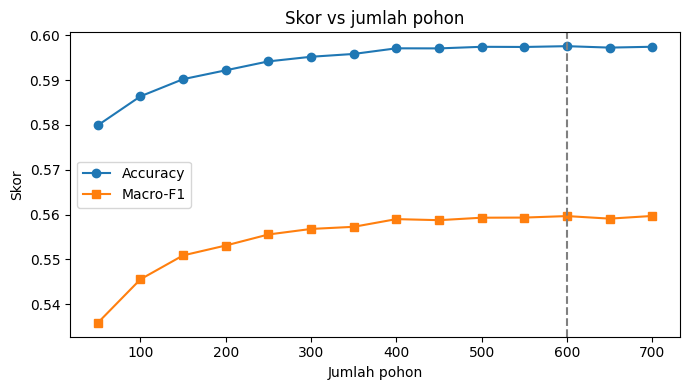

In [12]:
plt.figure(figsize=(7, 4))
plt.plot(curve["n_trees"], curve["accuracy"], marker="o", label="Accuracy")
plt.plot(curve["n_trees"], curve["f1_macro"], marker="s", label="Macro-F1")
plt.axvline(best_n, color="gray", linestyle="--")
plt.xlabel("Jumlah pohon"); plt.ylabel("Skor"); plt.title("Skor vs jumlah pohon"); plt.legend()
plt.tight_layout()
plt.savefig("../reports/figures/kurva_n_trees.png", dpi=120)
plt.show()

# **7. Evaluation**

In [13]:
Xt_test = tuned[:-1].transform(X_test)
y_pred = tuned.named_steps["algo"].predict(Xt_test, num_iteration=best_n)

print("Classification Report on Test Set:")
print(classification_report(y_test, y_pred))

Classification Report on Test Set:


              precision    recall  f1-score   support

     Grade 1       0.65      0.73      0.69     11034
     Grade 2       0.45      0.37      0.40     12216
     Grade 3       0.46      0.42      0.44     19098
     Grade 4       0.53      0.52      0.53     25738
     Grade 5       0.72      0.77      0.74     38607

    accuracy                           0.60    106693
   macro avg       0.56      0.56      0.56    106693
weighted avg       0.59      0.60      0.59    106693



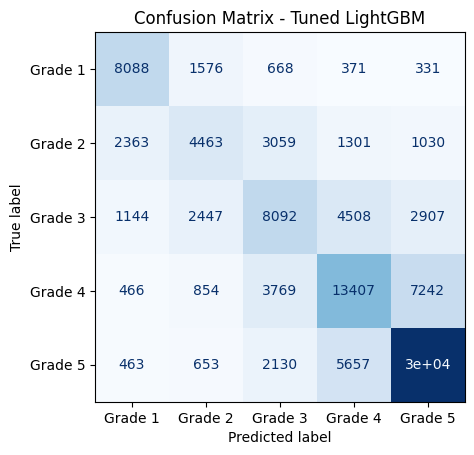

In [14]:
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, cmap="Blues", colorbar=False)
plt.title("Confusion Matrix - Tuned LightGBM")
plt.savefig("../reports/figures/confusion_matrix.png", dpi=120, bbox_inches="tight")
plt.show()

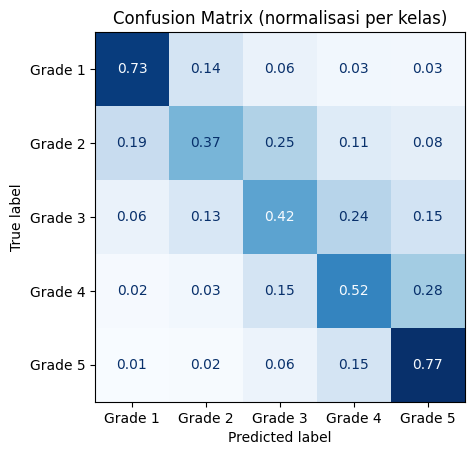

In [15]:
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, cmap="Blues", colorbar=False, normalize="true", values_format=".2f")
plt.title("Confusion Matrix (normalisasi per kelas)")
plt.savefig("../reports/figures/confusion_matrix_normalized.png", dpi=120, bbox_inches="tight")
plt.show()

In [16]:
lgbm_acc = accuracy_score(y_test, y_pred)
lgbm_f1 = f1_score(y_test, y_pred, average="macro")
base_acc = accuracy_score(y_test, y_pred_base)
base_f1 = f1_score(y_test, y_pred_base, average="macro")
summary = pd.DataFrame({
    "Model": ["Decision Tree", "LightGBM (awal, 200 pohon)", f"LightGBM tuned ({best_n} pohon)"],
    "Accuracy": [dt_acc, base_acc, lgbm_acc],
    "Macro-F1": [dt_f1, base_f1, lgbm_f1],
}).round(4)
summary

,Model,Accuracy,Macro-F1
0,Decision Tree,0.5526,0.5089
1,"LightGBM (awal, 200 pohon)",0.5929,0.5539
2,LightGBM tuned (600 pohon),0.5975,0.5597


### Feature importance

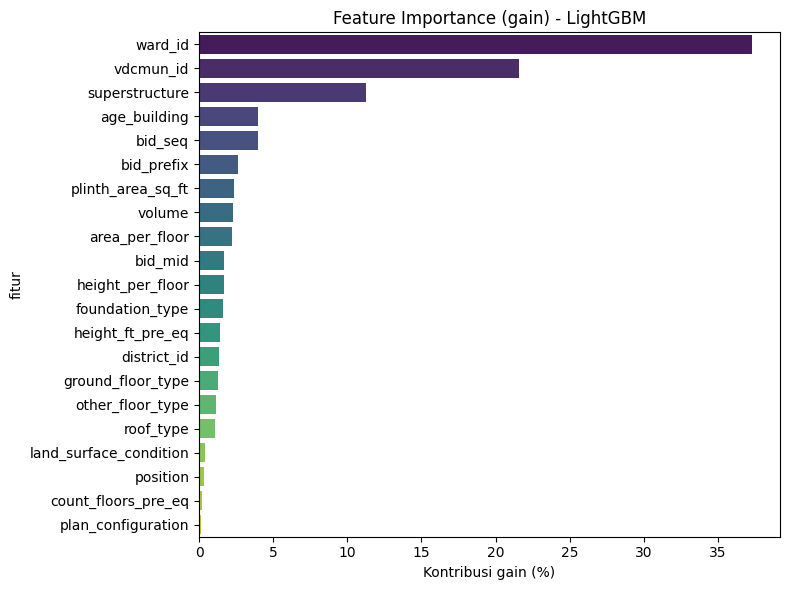

,fitur,gain,gain_pct
20,ward_id,1122730.09,37.32
19,vdcmun_id,650264.10,21.62
17,superstructure,338981.31,11.27
1,age_building,119277.60,3.96
9,bid_seq,118987.73,3.96
7,bid_prefix,79611.00,2.65
2,plinth_area_sq_ft,70739.11,2.35
6,volume,68518.97,2.28
4,area_per_floor,67037.70,2.23
8,bid_mid,50707.47,1.69


In [17]:
names = NUMERIC_COLUMNS + CATEGORICAL_COLUMNS
booster = tuned.named_steps["algo"].booster_
imp = pd.DataFrame({
    "fitur": names,
    "gain": booster.feature_importance(importance_type="gain", iteration=best_n),
}).sort_values("gain", ascending=False)
imp["gain_pct"] = 100 * imp["gain"] / imp["gain"].sum()

plt.figure(figsize=(8, 6))
sns.barplot(y="fitur", x="gain_pct", data=imp, palette="viridis")
plt.xlabel("Kontribusi gain (%)"); plt.title("Feature Importance (gain) - LightGBM")
plt.tight_layout()
plt.savefig("../reports/figures/feature_importance.png", dpi=120)
plt.show()
imp.round(2)

# **8. Final Fit & Save Model**
Model final dilatih ulang pada **seluruh data train** (80% + 20%) dengan parameter terbaik dan jumlah pohon = `best_n` x 1,1 (data lebih banyak).

In [18]:
final_n = int(best_n * 1.1)
t = time.time()
final_model = build_pipeline(n_estimators=final_n, **best_params)
final_model.fit(X, y, **get_fit_params())
print(f"Waktu final fit: {time.time() - t:.0f} detik | n_estimators = {final_n}")

Waktu final fit: 211 detik | n_estimators = 660


In [19]:
with open("../models/pipeline_lgbm_structural_damage.pkl", "wb") as f:
    pickle.dump(final_model, f)

metrics = {
    "best_params": {k: (v.item() if hasattr(v, "item") else v) for k, v in best_params.items()},
    "cv_accuracy_tuning": float(search.best_score_),
    "best_n_trees_holdout": best_n,
    "final_n_trees": final_n,
    "holdout": summary.set_index("Model").to_dict(orient="index"),
}
with open("../reports/metrics.json", "w") as f:
    json.dump(metrics, f, indent=2)
imp.to_csv("../reports/feature_importance.csv", index=False)
print(json.dumps(metrics, indent=2))

{
  "best_params": {
    "reg_lambda": 5.0,
    "num_leaves": 63,
    "min_child_samples": 100,
    "colsample_bytree": 0.7,
    "cat_smooth": 10
  },
  "cv_accuracy_tuning": 0.5647399997129509,
  "best_n_trees_holdout": 600,
  "final_n_trees": 660,
  "holdout": {
    "Decision Tree": {
      "Accuracy": 0.5526,
      "Macro-F1": 0.5089
    },
    "LightGBM (awal, 200 pohon)": {
      "Accuracy": 0.5929,
      "Macro-F1": 0.5539
    },
    "LightGBM tuned (600 pohon)": {
      "Accuracy": 0.5975,
      "Macro-F1": 0.5597
    }
  }
}
